In [52]:
import pandas as pd
import numpy as np
from sklearn import datasets
import matplotlib.pylab as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import RobustScaler
from sklearn.neural_network import MLPRegressor

In [41]:
# Load the dataset
from pathlib import Path

_candidates = [
    Path("data/processed/ECOLI_W_API.csv"),
    Path("../../data/processed/ECOLI_W_API.csv"),
]
_path = next((p for p in _candidates if p.exists()), None)
if _path is None:
    raise FileNotFoundError(
        "Could not find data/processed/ECOLI_W_API.csv. "
        "Run this notebook from the repo root or from src/modeling."
    )
df = pd.read_csv(_path)

# Normalize column names (remove spaces)
df.columns = df.columns.str.replace(' ', '')

# Define initial feature set
features = [
    'TEMPERATURE', 'HUMIDITY', 'PRECIPITATION', 'DEW', 'WINDSPEED', 'WINDGUST',
    'WINDDIR', 'PRESSURE', 'CLOUDCOVER', 'SOLARRADIATION', 'SOLARENERGY', 'UVINDEX'
]

# Fill missing values
df[features] = df[features].fillna(df[features].mean())

# Prepare dataset
x = df[features]
y = df['RESULT..MPN.100ML.']

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

df.head()

,LONGITUDE,LATITUDE,SAMPLE_DATE,SAMPLE_TIME,WATERSHED,SITE_TYPE,RESULT..MPN.100ML.,TEMPERATURE,HUMIDITY,PRECIPITATION,DEW,WINDSPEED,WINDGUST,WINDDIR,PRESSURE,CLOUDCOVER,SOLARRADIATION,SOLARENERGY,UVINDEX,CONDITIONS
0,-97.844469,30.273778,01/07/2025,08:45:00 AM,Barton Creek,Stream,43.5,30.0,47.64,0.0,12.5,2.0,13.2,15.0,1032.9,5.0,23.0,0.1,0.0,Clear
1,-97.844469,30.273778,08/07/2024,11:00:00 AM,Barton Creek,Stream,60.9,91.7,55.51,0.0,73.5,5.4,13.6,243.0,1012.5,4.8,752.0,2.7,8.0,Clear
2,-97.844469,30.273778,05/20/2024,01:00:00 PM,Barton Creek,Stream,12.0,88.8,52.90,0.0,69.4,7.3,19.7,166.0,1010.1,29.0,933.0,3.4,9.0,Partially cloudy
3,-97.844469,30.273778,03/05/2024,01:40:00 PM,Barton Creek,Stream,14.6,87.3,21.83,0.0,43.7,4.4,18.3,290.2,1009.2,0.0,875.0,3.2,9.0,Clear
4,-97.844469,30.273778,08/14/2023,09:45:00 AM,Barton Creek,Stream,4.0,82.9,75.22,0.0,74.2,6.3,17.7,203.0,1016.5,4.8,58.0,0.2,1.0,Clear


In [37]:
#Linear Regression
reg = linear_model.LinearRegression()
reg.fit(x, y)
y_pred = reg.predict(x)
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)
print("Coefficients:", reg.coef_)
print("Intercept:", reg.intercept_)
print("Mean Squared Error:", mse)
print("R² Score:", r2)

Coefficients: [-7.23691643e+01 -3.98114864e+01  7.22119573e+04  8.79569159e+01
 -2.81165405e+01 -5.56227259e+01 -4.64727800e-01 -8.41140102e+00
  5.61990845e+00 -8.93682532e+00  3.51102640e+03 -3.19761176e+02]
Intercept: 12676.624034870832
Mean Squared Error: 9158530.966294251
R² Score: 0.20729397519633286


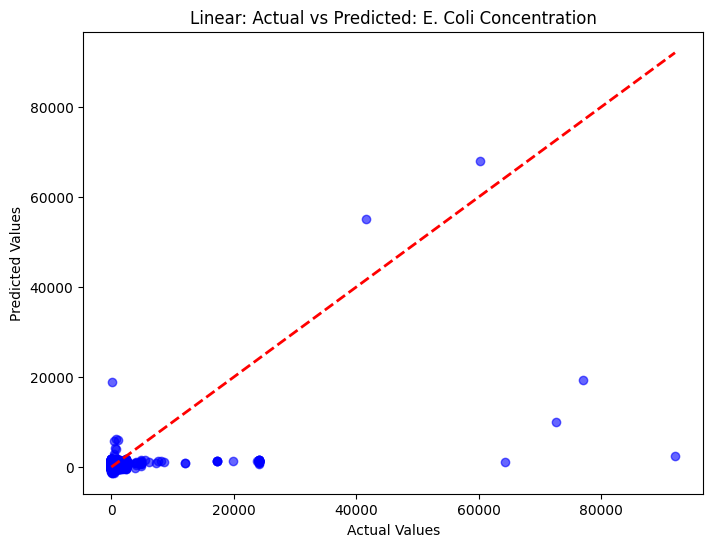

In [38]:
#Plotting Regression
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred, color='blue', alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', linewidth=2)  # Line of perfect prediction
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Linear: Actual vs Predicted: E. Coli Concentration')
plt.show()

In [39]:
#Huber Regression
reg = linear_model.HuberRegressor(max_iter=10000)
reg.fit(x, y)
y_pred = reg.predict(x)
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)
print("Coefficients:", reg.coef_)
print("Intercept:", reg.intercept_)
print("Mean Squared Error:", mse)
print("R² Score:", r2)

Coefficients: [ 1.05516177e+00  9.40067858e-01  3.99012097e-01  5.46498649e-01
 -3.96580549e+00  1.38931121e+00 -1.02626002e-01  3.07916265e-03
  4.35971756e-02  1.83362853e-02  1.87994192e-01 -3.18552839e+00]
Intercept: -0.015451028398511077
Mean Squared Error: 11780238.346903225
R² Score: -0.019624866212780034


In [ ]:
#Neural Net
nn_model = MLPRegressor(
    hidden_layer_sizes=(32,),            # Reduce the number of neurons and layers for speed
    activation='relu',                   # ReLU activation function for faster training
    max_iter=300,                        # Limit iterations (epochs) to 300
    solver='adam',                       # Adam solver for faster convergence
    early_stopping=True,                 # Enable early stopping
    n_iter_no_change=10,                 # Stop after 10 iterations with no improvement
    batch_size=32,                       # Mini-batch size
    random_state=42                      # For reproducibility
)

# Train the neural network model
nn_model.fit(x, y)

# Make predictions
y_pred_nn = nn_model.predict(x)

# Calculate performance metrics
mse_nn = mean_squared_error(y, y_pred_nn)
r2_nn = r2_score(y, y_pred_nn)

# Output results
print("Neural Network Results:")
print("Weights (Coefficients):")
print(nn_model.coefs_)  # Coefficients (weights) for each layer

print("Biases:")
print(nn_model.intercepts_)  # Biases for each layer

print("Mean Squared Error:", mse_nn)
print("R² Score:", r2_nn)

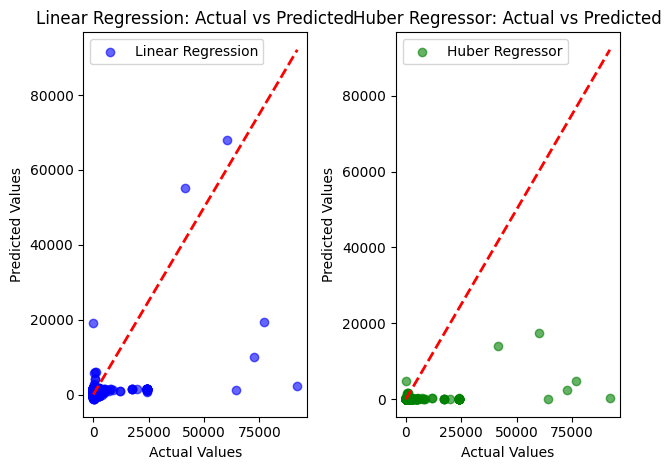

In [49]:
# Train Linear Regression model
reg_linear = linear_model.LinearRegression()
reg_linear.fit(X_scaled, y)
y_pred_linear = reg_linear.predict(X_scaled)

# Train Huber Regressor
reg_huber = linear_model.HuberRegressor(max_iter=10000)
reg_huber.fit(X_scaled, y)
y_pred_huber = reg_huber.predict(X_scaled)

#Train Neural Net
#nn_model = MLPRegressor(
#    hidden_layer_sizes=(32,),            # Reduce the number of neurons and layers for speed
#    activation='relu',                   # ReLU activation function for faster training
#    max_iter=300,                        # Limit iterations (epochs) to 300
#    solver='adam',                       # Adam solver for faster convergence
#    early_stopping=True,                 # Enable early stopping
#    n_iter_no_change=10,                 # Stop after 10 iterations with no improvement
#    batch_size=32,                       # Mini-batch size
#    random_state=42                      # For reproducibility
#)
#nn_model.fit(x, y)
#y_pred_nn = nn_model.predict(x)


# Plot both lines
# Linear Regression line
plt.subplot(1, 2, 1)
plt.scatter(y, y_pred_linear, color='blue', alpha=0.6, label='Linear Regression')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', linewidth=2)  # Line of perfect prediction
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Linear Regression: Actual vs Predicted')
plt.legend()

# Huber Regressor line
plt.subplot(1, 2, 2)
plt.scatter(y, y_pred_huber, color='green', alpha=0.6, label='Huber Regressor')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', linewidth=2)  # Line of perfect prediction
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Huber Regressor: Actual vs Predicted')
plt.legend()

# Neural Network line
#plt.subplot(1, 3, 3)
#plt.scatter(y, y_pred_nn, color='purple', alpha=0.6, label='Neural Network')
#plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', linewidth=2)  # Line of perfect prediction
#plt.xlabel('Actual Values')
#plt.ylabel('Predicted Values')
#plt.title('Neural Network: Actual vs Predicted')
#plt.legend()

plt.tight_layout()
plt.show()